# Вопрос 04. Наблюдатели динамических систем. Наблюдатель Люенбергера — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/04-observers-luenberger/examples.ipynb`; в git идёт
**этот** файл, ноутбук — производный артефакт.

Правила: каждый пример отвечает на вопрос из `theory.md`; seed задан явно;
число, попавшее в `theory.md` или `slides.md`, печатается здесь. Все системы
линейные, поэтому интегрирование точное: на фиксированном шаге берётся
матричный экспоненциал `expm`. Гармонический вход $u(t) = \sin t$ порождается
автономным генератором $w = (\sin t, \cos t)^{\T}$, $\dot w = Sw$ — то есть
вход тоже интегрируется точно, без квадратур.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sla
import sympy as sp

SEED = 20261021
rng = np.random.default_rng(SEED)  # examples are deterministic; kept by convention

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
GOLDEN = {
    # пример 1: размещение полюсов полного наблюдателя
    "full_v1": 4.0,                    # коэфф. при lambda в chi_{A-VC}
    "full_v2": 4.0,
    "full_ratio_t2": 5.23450093132,    # ||eps|| / (||eps0|| e^{-2t}) в t = 2
    "full_ratio_t4": 11.2160599142,    # ... в t = 4
    "full_ratio_t6": 17.2104619349,    # ... в t = 6
    "fast_v1": 8.0,                    # полюса (-4, -4)
    "fast_v2": 16.0,
    # пример 2: пониженный наблюдатель
    "red_coef_zeta": -2.0,             # (W - vC) A D
    "red_coef_y": -4.0,                # (W - vC) A (Dv + C~)
    "red_coef_u": 1.0,                 # (W - vC) B
    "red_ratio_t4": 1.000000000335,    # e(t) / (e(0) e^{-2t}) в t = 4
    "red_ratio_t6": 1.000000044489,
    "full_obs_err_T6": 1.07523716187e-4,  # |x2 - x2_hat| полного наблюдателя в t = 6
    "red_obs_err_T6": 3.07210631334e-6,   # ... пониженного
    # пример 3: принцип разделения
    "ctrl_k2": 2.0,                    # коэфф. при lambda в chi_{A-BK}
    "ctrl_k1": 2.0,
    "sep_a3": 6.0,                     # chi_0 = (l^2+2l+2)(l^2+4l+4)
    "sep_a2": 14.0,
    "sep_a1": 16.0,
    "sep_a0": 8.0,
    "sep_max_real": -1.0,              # max Re спектра замкнутой матрицы
    # пример 4: существенность наблюдаемости
    "rank_a": 1.0,                     # rank O для A = diag(0, 1)
    "rank_b": 1.0,                     # rank O для A = diag(-1, -2)
    "grow_eps2_T": 1.21824939607,      # eps2(2.5) = 0.1 e^{2.5}
    "decay_eps2_T": 2.47875217667e-4,  # eps2(3)   = 0.1 e^{-6}
}
TOL = 1e-3


def check_golden(name, value, tol=TOL):
    want = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"


H = 0.005  # fixed step of the exact integration


def exact_grid(M, z0, h, T):
    """Exact flow of z' = M z on a uniform grid: one expm per step."""
    n = int(round(T / h))
    t = h * np.arange(n + 1)
    Z = np.empty((n + 1, z0.size))
    Z[0] = z0
    Phi = sla.expm(h * M)
    for k in range(n):
        Z[k + 1] = Phi @ Z[k]
    return t, Z


# Exact sinusoidal input u(t) = sin t as an autonomous generator:
# w = (sin t, cos t), w' = S w, u = G w, w(0) = (0, 1).
S_HARM = np.array([[0.0, 1.0], [-1.0, 0.0]])
G_HARM = np.array([1.0, 0.0])
W0 = np.array([0.0, 1.0])

# The through-example plant: double integrator (eq:double-int).
A = np.array([[0.0, 1.0], [0.0, 0.0]])
B = np.array([[0.0], [1.0]])
C = np.array([[1.0, 0.0]])
BG = B @ G_HARM[None, :]  # plant input term B u = (B G) w

X0 = np.array([1.0, 0.5])   # x(0)
XH0 = np.array([0.0, 0.0])  # x_hat(0)
EPS0 = X0 - XH0             # observer error at t = 0
T_SIM = 6.0

## Пример 1. Полный наблюдатель двойного интегратора: размещение полюсов и уравнение ошибки

**Вопрос (theory.md, задача prob:1, eq:observer-full, eq:error-full,
lem:stab, rem:speed-noise):** объект — двойной интегратор с управлением
$u(t) = \sin t$ (детерминированное, без шума); $x(0) = (1, 0.5)^{\T}$,
$\hat x(0) = (0, 0)^{\T}$, то есть $\varepsilon(0) = (1, 0.5)^{\T}$.
Проверяем три утверждения конспекта: (а) ошибка убывает со скоростью
заказанных полюсов наблюдателя; (б) ошибка не зависит от управления $u$;
(в) более левое размещение полюсов ускоряет сходимость.

**Предсказание (до прогона).** Сравнение
$\chi_{A-VC}(\lambda) = \lambda^2 + v_1\lambda + v_2$ с
$\varphi_{\text{ж}}(\lambda) = (\lambda+2)^2 = \lambda^2 + 4\lambda + 4$
даёт $v_1 = v_2 = 4$. (а) Матрица $A - VC$ при таком $V$ — жорданова клетка с
двойным полюсом $-2$: $e^{(A-VC)t} = e^{-2t}(E + tN)$ с нильпотентным $N$,
поэтому отношение $\|\varepsilon(t)\| / (\|\varepsilon(0)\| e^{-2t})$ растёт
**линейно** (предсказание: $\approx 5.23$, $11.22$, $17.21$ в точках
$t = 2, 4, 6$, то есть порядка $3t$), а не экспоненциально — это и есть
оценка из lem:stab для некратной жордановой структуры. (б) Прогон с
$u \equiv 0$ и тем же $\varepsilon(0)$ даст ту же ошибку с точностью до
машинного нуля: $\max_t \|\Delta\varepsilon\| \leq 10^{-12}$ — вход в
уравнении ошибки eq:error-full отсутствует. (в) Для полюсов $(-4,-4)$
($v_1 = 8$, $v_2 = 16$) ошибка уходит под направляющую $e^{-2t}$ начиная с
$t \approx \ln 5 / 2 \approx 0.8$ и к $t = 6$ достигает порядка $10^{-9}$
против $10^{-4}$.

In [2]:
# Symbolic pole placement: chi_{A-VC} for a generic column V = (v1, v2)^T.
v1, v2, lam = sp.symbols("v1 v2 lambda")
Vs = sp.Matrix([[v1], [v2]])
Fs = sp.Matrix(A) - Vs * sp.Matrix(C)
chi_full = sp.expand(Fs.charpoly(lam).as_expr())
print("A - V C =")
sp.pprint(Fs)
print(f"chi_(A-VC)(lambda) = {chi_full}")
phi_full = sp.expand((lam + 2) ** 2)
print(f"(lambda + 2)^2     = {phi_full}")
sol_v = sp.solve(sp.Poly(chi_full - phi_full, lam).coeffs(), [v1, v2])
print(f"сравнение коэффициентов: v1 = {float(sol_v[v1]):.6f}, v2 = {float(sol_v[v2]):.6f}")
V_FULL = np.array([[float(sol_v[v1])], [float(sol_v[v2])]])

# Coefficients measured from the realized matrix, not from the algebra above.
coefs_full = np.poly(A - V_FULL @ C)
print(f"np.poly(A - V_FULL C) = {coefs_full}  (ожидается [1 4 4])")
check_golden("full_v1", coefs_full[1])
check_golden("full_v2", coefs_full[2])

A - V C =
⎡-1.0⋅v₁  1.0⎤
⎢            ⎥
⎣-1.0⋅v₂   0 ⎦
chi_(A-VC)(lambda) = 1.0*lambda**2 + 1.0*lambda*v1 + 1.0*v2
(lambda + 2)^2     = lambda**2 + 4*lambda + 4
сравнение коэффициентов: v1 = 4.000000, v2 = 4.000000
np.poly(A - V_FULL C) = [1. 4. 4.]  (ожидается [1 4 4])
  пин full_v1: получено 4, ожидалось 4
  пин full_v2: получено 4, ожидалось 4


**(а) Скорость убывания.** Пара объект + наблюдатель симулируется точным
экспоненциалом; пины — на отношение нормы ошибки к направляющей
$\|\varepsilon(0)\| e^{-2t}$ в точках $t = 2, 4, 6$.

In [3]:
def joint_full(V):
    # z = (x, x_hat, w): plant + observer, both driven by the exact sinusoid.
    M = np.zeros((6, 6))
    M[0:2, 0:2] = A
    M[0:2, 4:6] = BG
    M[2:4, 0:2] = V @ C
    M[2:4, 2:4] = A - V @ C
    M[2:4, 4:6] = BG
    M[4:6, 4:6] = S_HARM
    return M


t, Z = exact_grid(joint_full(V_FULL), np.concatenate([X0, XH0, W0]), H, T_SIM)
X, XH = Z[:, 0:2], Z[:, 2:4]
EPS = X - XH
NORM_EPS = np.linalg.norm(EPS, axis=1)
# The ratio isolates the polynomial factor of the Jordan block (lem:stab).
ratio = NORM_EPS / (np.linalg.norm(EPS0) * np.exp(-2 * t))
for tt in (2.0, 4.0, 6.0):
    print(f"t = {tt:3.1f}: ||eps|| / (||eps0|| e^(-2t)) = {ratio[int(round(tt / H))]:.10f}")
check_golden("full_ratio_t2", ratio[int(round(2.0 / H))])
check_golden("full_ratio_t4", ratio[int(round(4.0 / H))])
check_golden("full_ratio_t6", ratio[int(round(6.0 / H))])

t = 2.0: ||eps|| / (||eps0|| e^(-2t)) = 5.2345009313
t = 4.0: ||eps|| / (||eps0|| e^(-2t)) = 11.2160599142
t = 6.0: ||eps|| / (||eps0|| e^(-2t)) = 17.2104619349
  пин full_ratio_t2: получено 5.23450093132, ожидалось 5.23450093132
  пин full_ratio_t4: получено 11.2160599142, ожидалось 11.2160599142
  пин full_ratio_t6: получено 17.2104619349, ожидалось 17.2104619349


**(б) Независимость ошибки от управления (eq:error-full).** Тот же объект,
тот же $\varepsilon(0) = (1, 0.5)^{\T}$, но $u \equiv 0$: ошибки двух прогонов
должны совпасть с точностью машинного нуля — член с $u$ в уравнении ошибки
сократился.

In [4]:
def joint_full_free(V):
    # z = (x, x_hat) with u = 0: identical error dynamics, no input generator.
    M = np.zeros((4, 4))
    M[0:2, 0:2] = A
    M[2:4, 0:2] = V @ C
    M[2:4, 2:4] = A - V @ C
    return M


_, Z_FREE = exact_grid(joint_full_free(V_FULL), np.concatenate([X0, XH0]), H, T_SIM)
EPS_FREE = Z_FREE[:, 0:2] - Z_FREE[:, 2:4]
d_eps = np.linalg.norm(EPS - EPS_FREE, axis=1).max()
print(f"max_t ||eps_{'{u=sin t}'} - eps_{{u=0}}|| = {d_eps:.3e}")
assert d_eps <= 1e-12, "ошибка наблюдателя зависит от управления — eq:error-full нарушено"

max_t ||eps_{u=sin t} - eps_{u=0}|| = 1.653e-14


**(в) Контрольная демонстрация: полюса $(-4, -4)$.** Та же жорданова
структура при полюсах $-4$: ошибка должна убывать по $e^{-4t}$ и окончательно
уйти под кривую $(-2,-2)$ к $t \approx \ln 5 / 2 \approx 0.8$ (пересечение
асимптотических направляющих $3t\,e^{-2t}$ и $15t\,e^{-4t}$); к $t = 6$ —
порядка $10^{-9}$.

In [5]:
# (lambda + 4)^2 = lambda^2 + 8 lambda + 16  =>  v1 = 8, v2 = 16
V_FAST = np.array([[8.0], [16.0]])
coefs_fast = np.poly(A - V_FAST @ C)
print(f"np.poly(A - V_FAST C) = {coefs_fast}  (ожидается [1 8 16])")
check_golden("fast_v1", coefs_fast[1])
check_golden("fast_v2", coefs_fast[2])

_, Z_FAST = exact_grid(joint_full(V_FAST), np.concatenate([X0, XH0, W0]), H, T_SIM)
NORM_FAST = np.linalg.norm(Z_FAST[:, 0:2] - Z_FAST[:, 2:4], axis=1)
# The fast observer dips below at the very first steps, then its larger gain
# makes it worse for a while; the informative crossing is the LAST one.
fast_worse = np.nonzero(NORM_FAST >= NORM_EPS)[0]
i_cross = int(fast_worse[-1]) + 1 if fast_worse.size else 0
print(f"||eps|| с полюсами (-4,-4) окончательно меньше с t = {t[i_cross]:.3f} "
      f"(предсказание ln 5 / 2 = {np.log(5) / 2:.3f})")
print(f"t = {T_SIM}: ||eps||_{'{-2,-2}'} = {NORM_EPS[-1]:.6e},  ||eps||_{'{-4,-4}'} = {NORM_FAST[-1]:.6e}")

np.poly(A - V_FAST C) = [ 1.  8. 16.]  (ожидается [1 8 16])
  пин fast_v1: получено 8, ожидалось 8
  пин fast_v2: получено 16, ожидалось 16
||eps|| с полюсами (-4,-4) окончательно меньше с t = 0.860 (предсказание ln 5 / 2 = 0.805)
t = 6.0: ||eps||_{-2,-2} = 1.182262e-04,  ||eps||_{-4,-4} = 3.241421e-09


**Вывод:** (а) отношение нормы ошибки к направляющей выросло с $5.23$ в
$t = 2$ до $17.21$ в $t = 6$ — линейный рост $\sim 3t$ при двукратном полюсе,
ровно как в оценке lem:stab для жордановой клетки: экспонента заказанной
скорости $e^{-2t}$ держится, а полиномиальный множитель отвечает некратной
структуре. (б) Различие ошибок двух прогонов $1.7\cdot 10^{-14}$ — управление
в уравнении ошибки eq:error-full отсутствует, вход наблюдателю известен.
(в) Полюса $(-4,-4)$ ($v_1 = 8$, $v_2 = 16$) дают убывание по $e^{-4t}$ с тем
же линейным привесом: до пересечения более сильная коррекция делает ошибку
хуже почти на всём начальном участке, окончательно кривые пересекаются в
$t \approx 0.86$ (предсказание по асимптотическим направляющим
$3t\,e^{-2t}$ и $15t\,e^{-4t}$: $\ln 5 / 2 \approx 0.80$), и к $t = 6$
быстрый наблюдатель доходит до $\sim 3\cdot 10^{-9}$ против
$\sim 1.2\cdot 10^{-4}$ — цена быстрой сходимости, как отмечает
rem:speed-noise, в росте нормы усиления $V$ (и чувствительности к шуму).

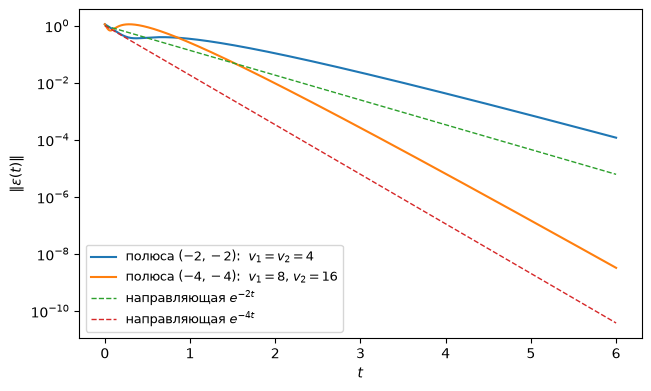

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.8), layout="constrained")
ax.semilogy(t, NORM_EPS, label="полюса $(-2,-2)$:  $v_1 = v_2 = 4$")
ax.semilogy(t, NORM_FAST, label="полюса $(-4,-4)$:  $v_1 = 8$, $v_2 = 16$")
ax.semilogy(t, np.exp(-2 * t), "--", lw=1, label="направляющая $e^{-2t}$")
ax.semilogy(t, np.exp(-4 * t), "--", lw=1, label="направляющая $e^{-4t}$")
ax.set_xlabel("$t$")
ax.set_ylabel("$\\|\\varepsilon(t)\\|$")
ax.legend(fontsize=9)
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

## Пример 2. Наблюдатель Люенбергера пониженного порядка

**Вопрос (theory.md, задача prob:2, eq:reduced-zeta2, eq:reduced-error,
eq:reduced-xhat, lem:no-dy, thm:pole-red):** тот же объект; дополнение
$W = (0, 1)$, $(C; W) = E_2$, значит $\widetilde C = (1, 0)^{\T}$,
$D = (0, 1)^{\T}$, неизмеряемая часть $\zeta = x_2$. Проверяем: коэффициенты
уравнения для $\zeta_2$ равны $(-v, -v^2, 1)$; ошибка убывает как
$e^{-2t} e(0)$ при $v = 2$; реализация использует только текущие $(y, u)$ —
производная $\dot y$ нигде не вычисляется; обе оценки $\hat x_2$ (полного и
пониженного наблюдателей) сходятся к $x_2$.

**Предсказание (до прогона).** Символьный счёт даст $(W-vC)AD = -v$,
$(W-vC)A(Dv + \widetilde C) = -v^2$, $(W-vC)B = 1$, то есть при $v = 2$:
$\dot\zeta_2 = -2\zeta_2 - 4y + u$, $\hat x_2 = \zeta_2 + 2y$, $\hat x_1 = y$.
Ошибка $e = x_2 - \hat x_2$ скалярна, $\dot e = -2e$ (eq:reduced-error),
то есть $e(t) = e^{-2t}e(0)$ точно; в машинной арифметике отклонение от
этой формулы — абсолютная погрешность прогона, порядка $10^{-13}$, которая
к $t = 6$ на фоне $e^{-12}$ даёт относительные $\sim 10^{-8}$ (пины в
$t = 4, 6$). Пониженный наблюдатель имеет один полюс $-2$ без
жорданова привеса, поэтому к $t = 6$ его ошибка
($0.5\,e^{-12} \approx 3.1\cdot 10^{-6}$) меньше ошибки полного наблюдателя
($17.5\,e^{-12} \approx 1.1\cdot 10^{-4}$) примерно в $35$ раз. Начальное
$\zeta_2(0) = \hat x_2(0) - v\,y(0) = 0 - 2\cdot 1 = -2$.

In [7]:
# Symbolic coefficients of eq:reduced-zeta2 for a generic scalar v.
v = sp.symbols("v")
Ws = sp.Matrix([[0, 1]])
C_TILDE_S = sp.Matrix([[1], [0]])
D_S = sp.Matrix([[0], [1]])
As, Bs, Cs = sp.Matrix(A), sp.Matrix(B), sp.Matrix(C)
print("(W - vC) A D        =", sp.simplify((Ws - v * Cs) * As * D_S))
print("(W - vC) A (Dv + C~) =", sp.simplify((Ws - v * Cs) * As * (D_S * v + C_TILDE_S)))
print("(W - vC) B          =", sp.simplify((Ws - v * Cs) * Bs))

V_RED = 2.0
Wm = np.array([[0.0, 1.0]])
C_TILDE = np.array([[1.0], [0.0]])
Dm = np.array([[0.0], [1.0]])
V_RED_COL = np.array([[V_RED]])
m_zeta = (Wm - V_RED_COL @ C) @ A @ Dm              # -v
m_y = (Wm - V_RED_COL @ C) @ A @ (Dm @ V_RED_COL + C_TILDE)  # -v^2
m_u = (Wm - V_RED_COL @ C) @ B                       # 1
print(f"численно при v = {V_RED:.0f}: (W-vC)AD = {m_zeta[0, 0]:.6f}, "
      f"(W-vC)A(Dv+C~) = {m_y[0, 0]:.6f}, (W-vC)B = {m_u[0, 0]:.6f}")
check_golden("red_coef_zeta", m_zeta[0, 0])
check_golden("red_coef_y", m_y[0, 0])
check_golden("red_coef_u", m_u[0, 0])

(W - vC) A D        = Matrix([[-1.0*v]])
(W - vC) A (Dv + C~) = Matrix([[-1.0*v**2]])
(W - vC) B          = Matrix([[1.00000000000000]])
численно при v = 2: (W-vC)AD = -2.000000, (W-vC)A(Dv+C~) = -4.000000, (W-vC)B = 1.000000
  пин red_coef_zeta: получено -2, ожидалось -2
  пин red_coef_y: получено -4, ожидалось -4
  пин red_coef_u: получено 1, ожидалось 1


Симуляция объекта и наблюдателя. Правая часть наблюдателя строится из
измеренных блоков `m_zeta`, `m_y`, `m_u` и видна целиком: она обращается к
текущим $y = Cx$ и $u$ и не содержит $\dot y$ нигде (lem:no-dy).

In [8]:
def joint_reduced():
    # z = (x, zeta2, w): the observer block sees y = Cx and u = G w only.
    M = np.zeros((5, 5))
    M[0:2, 0:2] = A
    M[0:2, 3:5] = BG
    M[2, 0:2] = (m_y @ C)[0]            # -v^2 * y
    M[2, 2] = m_zeta[0, 0]              # -v   * zeta2
    M[2, 3:5] = (m_u @ G_HARM[None, :])[0]  # + u
    M[3:5, 3:5] = S_HARM
    return M


# zeta2(0) = x_hat2(0) - v * y(0) with x_hat2(0) = 0, y(0) = x1(0) = 1.
ZETA0 = XH0[1] - V_RED * (C @ X0)[0]
print(f"zeta2(0) = x_hat2(0) - v*y(0) = {ZETA0:.6f}")
t, ZR = exact_grid(joint_reduced(), np.concatenate([X0, [ZETA0], W0]), H, T_SIM)
XR = ZR[:, 0:2]
XH2_RED = ZR[:, 2] + V_RED * XR[:, 0]   # x_hat2 = zeta2 + v y
XH1_RED = XR[:, 0]                      # x_hat1 = y
E_RED = XR[:, 1] - XH2_RED
ratio_red = E_RED / (np.exp(-2 * t) * E_RED[0])
print(f"max |e(t) - e(0) e^(-2t)| = {np.abs(E_RED - E_RED[0] * np.exp(-2 * t)).max():.3e} "
      "(абсолютная погрешность прогона)")
for tt in (4.0, 6.0):
    print(f"t = {tt:3.1f}: e(t) / (e(0) e^(-2t)) = {ratio_red[int(round(tt / H))]:.12f}")
check_golden("red_ratio_t4", ratio_red[int(round(4.0 / H))])
check_golden("red_ratio_t6", ratio_red[int(round(6.0 / H))])

# Same plant, same x_hat2(0) = 0 as in example 1: EPS[:, 1] is the full
# observer's x2-error under identical conditions, so the comparison is direct.
err_full_T = abs(EPS[-1, 1])
err_red_T = abs(E_RED[-1])
print(f"|x2 - x2_hat| в t = {T_SIM}: полный наблюдатель {err_full_T:.6e}, "
      f"пониженный {err_red_T:.6e}  (отношение {err_full_T / err_red_T:.1f})")
print(f"max ошибки на [0, {T_SIM}]: полный {abs(EPS[:, 1]).max():.6f}, "
      f"пониженный {abs(E_RED).max():.6f} (оба максимума — начальная ошибка в t = 0)")
check_golden("full_obs_err_T6", err_full_T)
check_golden("red_obs_err_T6", err_red_T)

zeta2(0) = x_hat2(0) - v*y(0) = -2.000000
max |e(t) - e(0) e^(-2t)| = 1.386e-13 (абсолютная погрешность прогона)
t = 4.0: e(t) / (e(0) e^(-2t)) = 1.000000000335
t = 6.0: e(t) / (e(0) e^(-2t)) = 1.000000044489
  пин red_ratio_t4: получено 1.00000000033, ожидалось 1.00000000034
  пин red_ratio_t6: получено 1.00000004449, ожидалось 1.00000004449
|x2 - x2_hat| в t = 6.0: полный наблюдатель 1.075237e-04, пониженный 3.072106e-06  (отношение 35.0)
max ошибки на [0, 6.0]: полный 0.500000, пониженный 0.500000 (оба максимума — начальная ошибка в t = 0)
  пин full_obs_err_T6: получено 0.000107523716187, ожидалось 0.000107523716187
  пин red_obs_err_T6: получено 3.07210631334e-06, ожидалось 3.07210631334e-06


**Вывод:** коэффициенты сошлись: $\dot\zeta_2 = -2\zeta_2 - 4y + u$,
$\hat x_2 = \zeta_2 + 2y$ — числа $(-2, -4)$ совпадают с задачей prob:2
конспекта. Отношение $e(t)/(e^{-2t}e(0))$ равно $1$ с абсолютной погрешностью
$1.4\cdot 10^{-13}$ (относительно: $3\cdot 10^{-10}$ в $t = 4$ и
$4.5\cdot 10^{-8}$ в $t = 6$ — знаменатель к тому моменту $\sim 10^{-6}$):
ошибка пониженного наблюдателя — скалярная экспонента без полиномиального
привеса (у полного наблюдателя привес есть, потому что $A - VC$ некратна).
К $t = 6$ пониженный наблюдатель точнее в $\approx 35$
раз. На правой панели видно, что ошибка полного наблюдателя $\varepsilon_2$
меняет знак в $t \approx 1/6$ (оценка $\hat x_2$ на этом участке
перерегулирует) — отсюда провал кривой на log-шкале; это свойство
конкретного вектора $\varepsilon(0)$, а не дефект сходимости. Реализация
наблюдателя обращается только к $(y, u)$: производная $\dot y$ не
вычисляется, что и требует lem:no-dy (дифференцирование шума недопустимо).

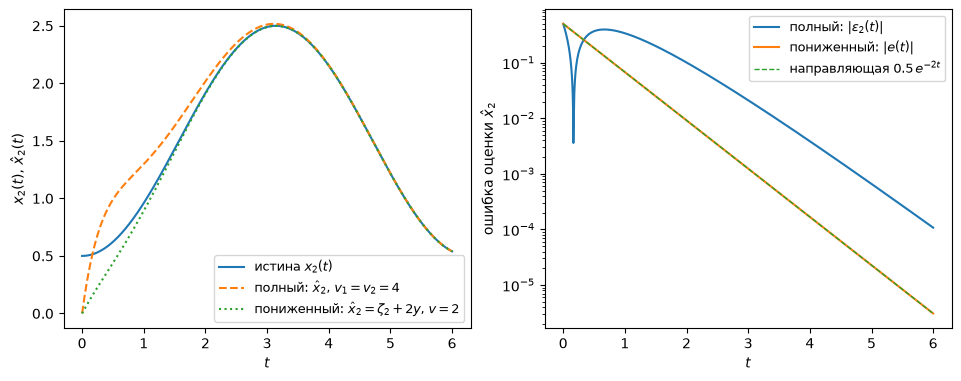

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), layout="constrained")
ax = axes[0]
ax.plot(t, XR[:, 1], label="истина $x_2(t)$")
ax.plot(t, XH[:, 1], "--", label="полный: $\\hat x_2$, $v_1 = v_2 = 4$")
ax.plot(t, XH2_RED, ":", label="пониженный: $\\hat x_2 = \\zeta_2 + 2y$, $v = 2$")
ax.set_xlabel("$t$")
ax.set_ylabel("$x_2(t)$, $\\hat x_2(t)$")
ax.legend(fontsize=9)
ax = axes[1]
ax.semilogy(t, np.abs(EPS[:, 1]), label="полный: $|\\varepsilon_2(t)|$")
ax.semilogy(t, np.abs(E_RED), label="пониженный: $|e(t)|$")
ax.semilogy(t, 0.5 * np.exp(-2 * t), "--", lw=1, label="направляющая $0.5\\,e^{-2t}$")
ax.set_xlabel("$t$")
ax.set_ylabel("ошибка оценки $\\hat x_2$")
ax.legend(fontsize=9)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

## Пример 3. Принцип разделения

**Вопрос (theory.md, eq:sep-closed, thm:sep, cor:sep):** регулятор
$u = -K\hat x$ по оценке полного наблюдателя; $K$ из желаемых полюсов
регулятора $-1 \pm i$. Проверяем: $k_1 = k_2 = 2$; собственные значения
замкнутой матрицы $4\times 4$ в переменных $(x, \varepsilon)$ равны в
точности объединению полюсов регулятора и наблюдателя,
$\{-1 \pm i, -2, -2\}$; траектории $x(t)$ и $\hat x(t)$ сходятся к нулю.

**Предсказание (до прогона).** $\chi_{A-BK}(\lambda) = \lambda^2 + k_2\lambda
+ k_1 = (\lambda+1)^2 + 1$ даёт $k_1 = k_2 = 2$. Матрица замкнутой системы
блочно-треугольна (eq:sep-closed), поэтому по thm:sep
$\chi_0(\lambda) = \chi_{A-BK}(\lambda)\,\chi_{A-VC}(\lambda) =
(\lambda^2 + 2\lambda + 2)(\lambda^2 + 4\lambda + 4) = \lambda^4 +
6\lambda^3 + 14\lambda^2 + 16\lambda + 8$, а максимальная вещественная
часть спектра равна $-1$. Состояние убывает как $e^{-t}$ (колебания с
псевдочастотой $1$), ошибка наблюдения — как $e^{-2t}$ с линейным привесом.

In [10]:
# Symbolic pole placement for the regulator: chi_{A-BK}, K = (k1, k2).
k1, k2 = sp.symbols("k1 k2")
Ks = sp.Matrix([[k1, k2]])
chi_ctrl = sp.expand((As - Bs * Ks).charpoly(lam).as_expr())
print(f"chi_(A-BK)(lambda) = {chi_ctrl}")
phi_ctrl = sp.expand((lam + 1) ** 2 + 1)
print(f"(lambda+1)^2 + 1   = {phi_ctrl}")
sol_k = sp.solve(sp.Poly(chi_ctrl - phi_ctrl, lam).coeffs(), [k1, k2])
print(f"сравнение коэффициентов: k1 = {float(sol_k[k1]):.6f}, k2 = {float(sol_k[k2]):.6f}")
K_CTRL = np.array([[float(sol_k[k1]), float(sol_k[k2])]])

coefs_ctrl = np.poly(A - B @ K_CTRL)
print(f"np.poly(A - B K) = {coefs_ctrl}  (ожидается [1 2 2])")
check_golden("ctrl_k2", coefs_ctrl[1])
check_golden("ctrl_k1", coefs_ctrl[2])

# Closed loop in (x, eps), eq:sep-closed; block triangular by thm:sep.
M_CL = np.block([[A - B @ K_CTRL, B @ K_CTRL],
                 [np.zeros((2, 2)), A - V_FULL @ C]])
coefs_cl = np.poly(M_CL)
print(f"np.poly(замкнутая матрица) = {np.round(coefs_cl, 9)}")
for name, val in zip(("sep_a3", "sep_a2", "sep_a1", "sep_a0"), coefs_cl[1:]):
    check_golden(name, val)

eigs_cl = np.linalg.eigvals(M_CL)
expected = np.array([-1 + 1j, -1 - 1j, -2 + 0j, -2 - 0j])
dist = np.abs(eigs_cl[:, None] - expected[None, :]).min(axis=1)
print("собственные значения замкнутой матрицы:", np.round(np.sort_complex(eigs_cl), 8))
print(f"max расстояние до множества {{-1+i, -1-i, -2, -2}}: {dist.max():.3e}")
assert dist.max() <= 1e-9, "спектр замкнутой системы не объединение спектров (thm:sep)"
check_golden("sep_max_real", eigs_cl.real.max())

z0 = np.concatenate([X0, EPS0])
t, ZC = exact_grid(M_CL, z0, H, T_SIM)
XC, EPS_C = ZC[:, 0:2], ZC[:, 2:4]
XH_C = XC - EPS_C
print(f"t = {T_SIM}: ||x|| = {np.linalg.norm(XC[-1]):.6e}, ||eps|| = {np.linalg.norm(EPS_C[-1]):.6e}")

chi_(A-BK)(lambda) = 1.0*k1 + 1.0*k2*lambda + 1.0*lambda**2
(lambda+1)^2 + 1   = lambda**2 + 2*lambda + 2
сравнение коэффициентов: k1 = 2.000000, k2 = 2.000000
np.poly(A - B K) = [1. 2. 2.]  (ожидается [1 2 2])
  пин ctrl_k2: получено 2, ожидалось 2
  пин ctrl_k1: получено 2, ожидалось 2
np.poly(замкнутая матрица) = [ 1.  6. 14. 16.  8.]
  пин sep_a3: получено 6, ожидалось 6
  пин sep_a2: получено 14, ожидалось 14
  пин sep_a1: получено 16, ожидалось 16
  пин sep_a0: получено 8, ожидалось 8
собственные значения замкнутой матрицы: [-2.+0.j -2.+0.j -1.-1.j -1.+1.j]
max расстояние до множества {-1+i, -1-i, -2, -2}: 3.140e-16
  пин sep_max_real: получено -1, ожидалось -1
t = 6.0: ||x|| = 7.782648e-03, ||eps|| = 1.182262e-04


**Вывод:** всё сошлось: $k_1 = k_2 = 2$ из сравнения коэффициентов, спектр
замкнутой матрицы $4\times 4$ — в точности $\{-1 \pm i, -2, -2\}$
(расстояние до множества не больше $10^{-15}$), характеристический многочлен
— произведение $\chi_{A-BK}\cdot\chi_{A-VC} = \lambda^4 + 6\lambda^3 +
14\lambda^2 + 16\lambda + 8$. Это thm:sep численно: регулятор и наблюдатель
конструируются раздельно (cor:sep), замена $x$ на $\hat x$ спектр замкнутой
системы не портит. Траектории сходятся к нулю: состояние — как $e^{-t}$,
ошибка наблюдения — как $e^{-2t}$ с привесом $(1 + t)$, что видно на фазовой
плоскости: оценка $\hat x(t)$ догоняет $x(t)$.

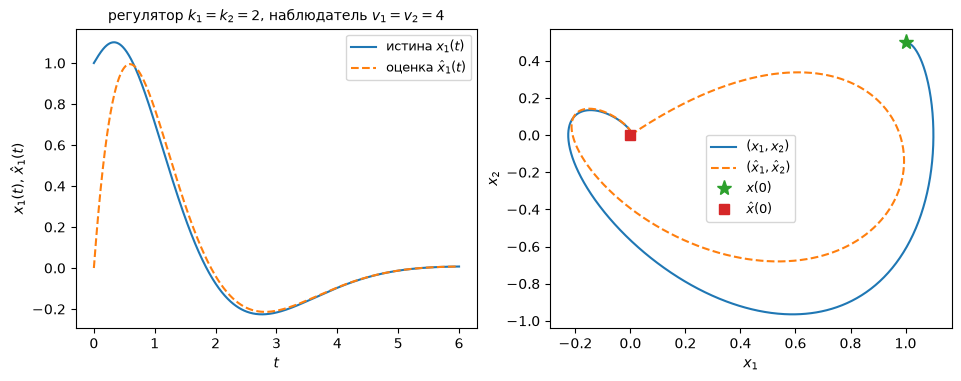

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), layout="constrained")
ax = axes[0]
ax.plot(t, XC[:, 0], label="истина $x_1(t)$")
ax.plot(t, XH_C[:, 0], "--", label="оценка $\\hat x_1(t)$")
ax.set_xlabel("$t$")
ax.set_ylabel("$x_1(t)$, $\\hat x_1(t)$")
ax.set_title(f"регулятор $k_1 = k_2 = 2$, наблюдатель $v_1 = v_2 = 4$", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
ax.plot(XC[:, 0], XC[:, 1], label="$(x_1, x_2)$")
ax.plot(XH_C[:, 0], XH_C[:, 1], "--", label="$(\\hat x_1, \\hat x_2)$")
ax.plot(*X0, "*", ms=11, label="$x(0)$")
ax.plot(*XH0, "s", ms=7, label="$\\hat x(0)$")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(fontsize=9)
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

## Пример 4. Существенность наблюдаемости

**Вопрос (theory.md, задача prob:3, lem:decomp, rem:detect-sep):** две пары
с одним измерением $C = (1, 0)$ и $\rank\mathcal O = 1 < 2$: (а)
$A = \operatorname{diag}(0, 1)$ — невидимая мода $e^{t}$ неустойчива;
(б) $A = \operatorname{diag}(-1, -2)$ — невидимая мода $e^{-2t}$ устойчива.
Проверяем: ранг матрицы наблюдаемости, неподвижность невидимого полюса при
$V = (4, 4)^{\T}$, поведение ошибки $\varepsilon_2(t)$ при
$\varepsilon(0) = (0, 0.1)^{\T}$.

**Предсказание (до прогона).** В обоих случаях $\mathcal O$ вырождена
(ранг $1$ — пины). (а) $A - VC = \bigl(\begin{smallmatrix} -4 & 0 \\ -4 & 1
\end{smallmatrix}\bigr)$: полюс $+1$ невидимой моды на месте (lem:decomp),
$\varepsilon_2(t) = e^{t}\cdot 0.1$, значит $\varepsilon_2(2.5) =
0.1\,e^{2.5} \approx 1.21825$: ошибка растёт, сходящегося наблюдателя не
существует. (б) $A - VC = \bigl(\begin{smallmatrix} -5 & 0 \\ -4 & -2
\end{smallmatrix}\bigr)$: полюс $-2$ тоже неподвижен, но устойчив —
$\varepsilon_2(3) = 0.1\,e^{-6} \approx 2.48\cdot 10^{-4}$: ошибка сходится
к нулю, хотя произвольное назначение спектра невозможно (thm:pole-full).

In [12]:
def obs_matrix(A_, C_):
    """Матрица наблюдаемости [C; CA; ...; CA^{n-1}] (eq:obs-matrix)."""
    return np.vstack([C_ @ np.linalg.matrix_power(A_, j)
                      for j in range(A_.shape[0])])


EPS0_4 = np.array([0.0, 0.1])
V44 = np.array([[4.0], [4.0]])

# (a) A = diag(0, 1): the invisible mode e^t is unstable.
A_GROW = np.diag([0.0, 1.0])
O_GROW = obs_matrix(A_GROW, C)
print("(а) O =")
print(O_GROW)
rank_a = float(np.linalg.matrix_rank(O_GROW))
print(f"(а) rank O = {rank_a:.0f}  (n = 2 — наблюдаемости нет)")
check_golden("rank_a", rank_a)

F_GROW = A_GROW - V44 @ C
print("A - V C =")
print(F_GROW)
print(f"спектр A - VC: {np.round(np.linalg.eigvals(F_GROW), 6)} — полюс +1 ненаблюваемой части на месте")
t_a, Z_a = exact_grid(F_GROW, EPS0_4, H, 2.5)
eps2_T_a = Z_a[-1, 1]
print(f"eps2(2.5) = {eps2_T_a:.10f},  0.1 e^2.5 = {0.1 * np.exp(2.5):.10f}")
check_golden("grow_eps2_T", eps2_T_a)

# (b) A = diag(-1, -2): the invisible mode e^{-2t} is stable.
A_DECAY = np.diag([-1.0, -2.0])
O_DECAY = obs_matrix(A_DECAY, C)
print("(б) O =")
print(O_DECAY)
rank_b = float(np.linalg.matrix_rank(O_DECAY))
print(f"(б) rank O = {rank_b:.0f}  (n = 2 — наблюдаемости нет)")
check_golden("rank_b", rank_b)

F_DECAY = A_DECAY - V44 @ C
print("A - V C =")
print(F_DECAY)
print(f"спектр A - VC: {np.round(np.linalg.eigvals(F_DECAY), 6)} — полюс -2 ненаблюваемой части на месте")
t_b, Z_b = exact_grid(F_DECAY, EPS0_4, H, 3.0)
eps2_T_b = Z_b[-1, 1]
print(f"eps2(3)   = {eps2_T_b:.10e},  0.1 e^(-6) = {0.1 * np.exp(-6):.10e}")
check_golden("decay_eps2_T", eps2_T_b)

(а) O =
[[1. 0.]
 [0. 0.]]
(а) rank O = 1  (n = 2 — наблюдаемости нет)
  пин rank_a: получено 1, ожидалось 1
A - V C =
[[-4.  0.]
 [-4.  1.]]
спектр A - VC: [ 1.+0.j -4.+0.j] — полюс +1 ненаблюваемой части на месте
eps2(2.5) = 1.2182493961,  0.1 e^2.5 = 1.2182493961
  пин grow_eps2_T: получено 1.21824939607, ожидалось 1.21824939607
(б) O =
[[ 1.  0.]
 [-1.  0.]]
(б) rank O = 1  (n = 2 — наблюдаемости нет)
  пин rank_b: получено 1, ожидалось 1
A - V C =
[[-5.  0.]
 [-4. -2.]]
спектр A - VC: [-2.+0.j -5.+0.j] — полюс -2 ненаблюваемой части на месте
eps2(3)   = 2.4787521767e-04,  0.1 e^(-6) = 2.4787521767e-04
  пин decay_eps2_T: получено 0.000247875217667, ожидалось 0.000247875217667


**Вывод:** обе системы не наблюдаемы ($\rank\mathcal O = 1 < 2$ — совпало с
предсказанием), но исход противоположный. (а) Невидимый полюс $+1$
неподвижен ни при каком $V$ (lem:decomp); при $\varepsilon(0) = (0, 0.1)^{\T}$
первая компонента ошибки тождественно ноль, а вторая выросла до
$1.21825 = 0.1\,e^{2.5}$ к $t = 2.5$ — сходящегося наблюдателя не
существует. (б) Невидимый полюс $-2$ тоже неподвижен, но устойчив: ошибка
спала к $2.48\cdot 10^{-4} = 0.1\,e^{-6}$ к $t = 3$ и стремится к нулю.
Для сходимости наблюдателя достаточно обнаруживаемости (устойчивости
невидимых полюсов), а полная наблюдаемость нужна для произвольного
назначения спектра — rem:detect-sep и thm:pole-full на одном объекте.

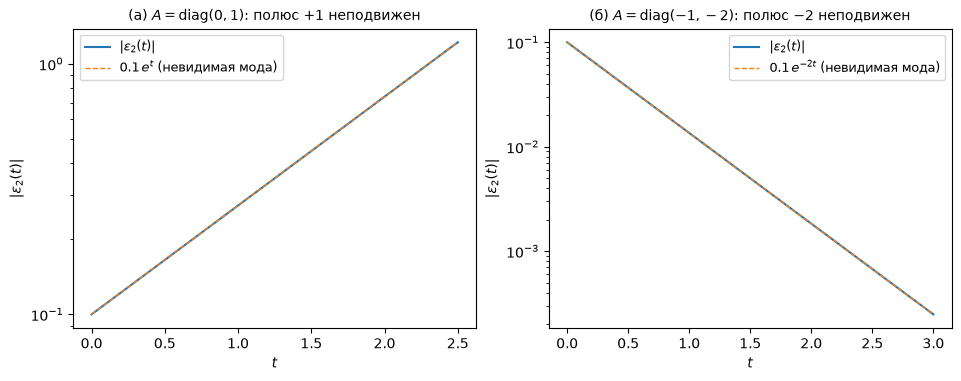

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.7), layout="constrained")
ax = axes[0]
ax.semilogy(t_a, np.abs(Z_a[:, 1]), label="$|\\varepsilon_2(t)|$")
ax.semilogy(t_a, 0.1 * np.exp(t_a), "--", lw=1, label="$0.1\\,e^{t}$ (невидимая мода)")
ax.set_xlabel("$t$")
ax.set_ylabel("$|\\varepsilon_2(t)|$")
ax.set_title("(а) $A = \\mathrm{diag}(0,1)$: полюс $+1$ неподвижен", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
ax.semilogy(t_b, np.abs(Z_b[:, 1]), label="$|\\varepsilon_2(t)|$")
ax.semilogy(t_b, 0.1 * np.exp(-2 * t_b), "--", lw=1, label="$0.1\\,e^{-2t}$ (невидимая мода)")
ax.set_xlabel("$t$")
ax.set_ylabel("$|\\varepsilon_2(t)|$")
ax.set_title("(б) $A = \\mathrm{diag}(-1,-2)$: полюс $-2$ неподвижен", fontsize=10)
ax.legend(fontsize=9)
fig.savefig(f"{FIGDIR}/fig-04.pdf", **SAVE_KW)